# Testing the scenario widget

A check that the widget of [The scenarios with sliders](chile_scenario_widget.ipynb) makes the
scenarios it should. The five scenarios are run through the widget the way a user runs them, and
again with `upd` over the same years. The two solutions must be the same.

In [1]:
from modelclass import model
from chile_widgets import scenario_widget
import pandas as pd
%matplotlib inline

model.widescreen()
model.scroll_off()

<IPython.core.display.Javascript object>

In [2]:
mchile, bline = model.modelload('data/chilepens', run=True, keep='Baseline')

# shares of GDP are shown multiplied by 100, so the chart titles say percent
pct = {v: d.replace('share of GDP', 'percent of GDP')
       for v, d in mchile.var_description.items() if 'share of GDP' in d}

Zipped file read:  data\chilepens.pcim


## The scenarios through the widget

For each scenario the code does what a user does: reset the sliders, move the scenario's slider,
type the name and press **Run scenario**.

In [3]:
ui = scenario_widget(mchile)
winput = ui.datawidget                     # the sliders, one tab per shock

# the tab and the slider value of each scenario
shocks = {
    'VAT +2 pp':                     (0, 0.02),
    'Pension benefits +0.5% of GDP': (1, 0.005),
    'Health elasticity 0.50':        (2, 0.50),
    'Female participation +8 pp':    (3, 0.08),
    'Copper price -20%':             (4, -20),
}

for name, (tab, value) in shocks.items():
    ui.reset(None)                                    # Reset to start
    winput.datachildren[tab].wset[0].value = value    # move the slider
    ui.wname.value = name                             # Scenario name
    ui.run(None)                                      # Run scenario

## The same scenarios with `upd`

The sliders act on 2025–2070, so the `upd` shocks do too. Both start from the widget's
baseline.

In [4]:
upd_shocks = {
    'VAT +2 pp':                     '<2025 2070> TAU_CONS + 0.02',
    'Pension benefits +0.5% of GDP': '<2025> G_P_STEP + 0.005',
    'Health elasticity 0.50':        '<2025 2070> HEALTH_EL = 0.50',
    'Female participation +8 pp':    '<2025 2070> P_F_1559 + 0.08',
    'Copper price -20%':             '<2025 2070> PCOPPER_SS * 0.8',
}

# the widget's solutions, before the runs below
widget = {name: mchile.keep_solutions[name].copy() for name in upd_shocks}

# a model call reuses the options of the last one, here the widget's keep=<scenario name>,
# so reset_options=True: these runs are not kept
endo = sorted(mchile.endogene)
largest = {}
for name, shock in upd_shocks.items():
    res = mchile(ui.baseline.upd(shock), 2025, 2070, silent=1, reset_options=True)
    largest[name] = (res - widget[name]).loc[2025:2070, endo].abs().max().max()

check = pd.Series(largest, name='Largest difference, all endogenous variables 2025-2070')
assert check.max() < 1e-8, check
check.to_frame()

,"Largest difference, all endogenous variables 2025-2070"
VAT +2 pp,0.0
Pension benefits +0.5% of GDP,0.0
Health elasticity 0.50,0.0
Female participation +8 pp,0.0
Copper price -20%,0.0


The differences are all zero: the widget makes exactly the scenarios it should.

## Compared with Five scenarios

Gross government debt in the five scenarios run through the widget:

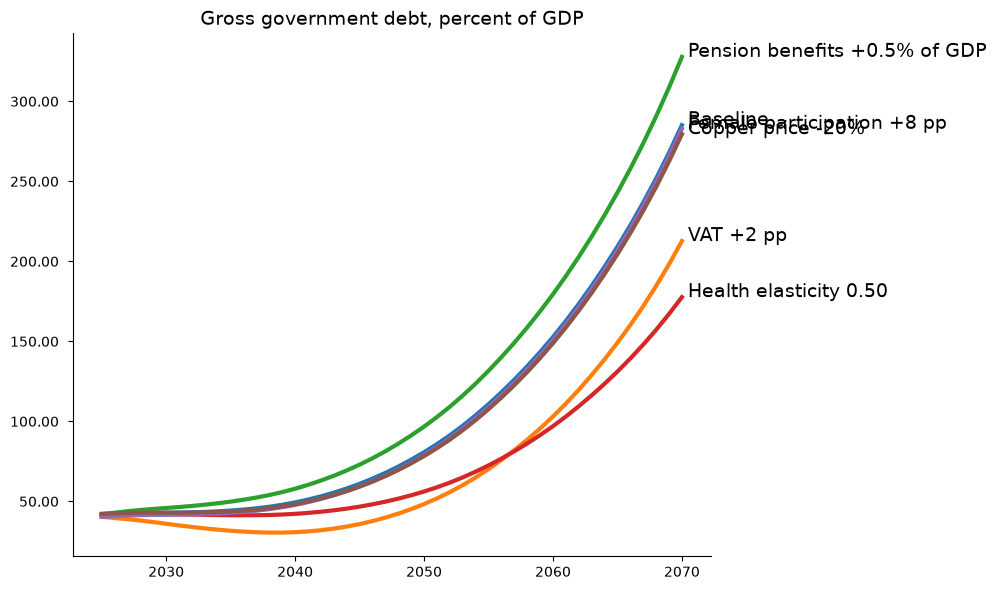

In [5]:
mchile.plot('B_G', scenarios='*', datatype='level', mul=100, custom_description=pct, legend=False).show

Health and copper give the results of [Five scenarios](chile_scenarios.ipynb) exactly,
because their shocks cover the same years in both notebooks. The other three start earlier
through the widget. In 2070 debt is 72.4 points lower with the VAT increase (68.5 in Five
scenarios) and 42.7 points higher with the pension step (41.8). With higher female participation
it is 2.3 points lower (2.5): the jump helps debt earlier, by 1.3 points in 2030 against 0.6, but
by 2070 the two paths are nearly the same.